In [1]:
import pandas as pd 
import numpy as np
import sys
from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [2]:
BASE_DIR = Path.cwd().resolve().parent
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))
batch_reactor_data = pd.read_parquet(BASE_DIR / "data" / "processed" / "batch_reactor_data.parquet")

In [3]:
batch_reactor_data.head()

,batch_id,reactor_id,operator_shift,feed_purity,catalyst_lot,batch_start,yield_pct,ambient_humidity,temp_c_mean,temp_c_std,...,feed_rate_fraction_unknow,feed_rate_get_quantille_05,feed_rate_get_quantille_90,ph_mean,ph_std,ph_min,ph_max,ph_fraction_unknow,ph_get_quantille_05,ph_get_quantille_90
0,0,R5,A,0.963375,LOT-119,2022-01-01 00:52:00,59.521627,54.050379,70.830789,12.520624,...,0.050000,49.923121,51.566892,6.437876,0.115852,6.176987,6.676187,0.033333,6.262175,6.622747
1,1,R7,A,0.962882,LOT-002,2022-01-01 01:25:00,69.576301,52.904138,73.444318,13.847610,...,0.022222,48.353880,50.017927,7.150818,0.109881,6.939894,7.392830,0.033333,6.985752,7.327390
2,2,R2,A,0.959922,LOT-119,2022-01-01 00:27:00,54.799699,51.992843,70.433695,12.120622,...,0.022222,51.052669,52.528677,6.763659,0.114753,6.450911,7.043655,0.038889,6.585890,6.947063
3,3,R3,B,0.965263,LOT-003,2022-01-01 00:47:00,43.799610,59.895421,77.007976,13.874411,...,0.050000,48.355655,50.036517,6.427968,0.116073,6.177925,6.716607,0.027778,6.229723,6.629469
4,4,R8,NIGHT,0.987677,LOT-061,2022-01-01 01:59:00,58.296184,47.522894,66.749413,11.242480,...,0.050000,52.107783,53.583611,6.942626,0.125743,6.631501,7.197336,0.033333,6.749315,7.158225


In [4]:
mask = batch_reactor_data['feed_purity'] > 1
batch_reactor_data.loc[mask, 'feed_purity'] = (batch_reactor_data.loc[mask, 'feed_purity'] / 100)

In [5]:
batch_reactor_data

,batch_id,reactor_id,operator_shift,feed_purity,catalyst_lot,batch_start,yield_pct,ambient_humidity,temp_c_mean,temp_c_std,...,feed_rate_fraction_unknow,feed_rate_get_quantille_05,feed_rate_get_quantille_90,ph_mean,ph_std,ph_min,ph_max,ph_fraction_unknow,ph_get_quantille_05,ph_get_quantille_90
0,0,R5,A,0.963375,LOT-119,2022-01-01 00:52:00,59.521627,54.050379,70.830789,12.520624,...,0.050000,49.923121,51.566892,6.437876,0.115852,6.176987,6.676187,0.033333,6.262175,6.622747
1,1,R7,A,0.962882,LOT-002,2022-01-01 01:25:00,69.576301,52.904138,73.444318,13.847610,...,0.022222,48.353880,50.017927,7.150818,0.109881,6.939894,7.392830,0.033333,6.985752,7.327390
2,2,R2,A,0.959922,LOT-119,2022-01-01 00:27:00,54.799699,51.992843,70.433695,12.120622,...,0.022222,51.052669,52.528677,6.763659,0.114753,6.450911,7.043655,0.038889,6.585890,6.947063
3,3,R3,B,0.965263,LOT-003,2022-01-01 00:47:00,43.799610,59.895421,77.007976,13.874411,...,0.050000,48.355655,50.036517,6.427968,0.116073,6.177925,6.716607,0.027778,6.229723,6.629469
4,4,R8,NIGHT,0.987677,LOT-061,2022-01-01 01:59:00,58.296184,47.522894,66.749413,11.242480,...,0.050000,52.107783,53.583611,6.942626,0.125743,6.631501,7.197336,0.033333,6.749315,7.158225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11001,11105,R4,NIGHT,0.979077,LOT-079,2022-02-24 00:14:00,16.920549,56.449530,83.345778,15.640989,...,0.083333,48.731958,50.108721,7.222210,0.115377,6.988362,7.459625,0.083333,7.042820,7.398848
11002,11106,R8,C,0.955476,LOT-033,2022-02-24 01:13:00,81.626458,55.170213,79.698375,15.127423,...,0.050000,49.452142,50.971300,7.503548,0.122970,7.255009,7.770637,0.027778,7.309763,7.676029
11003,11107,R8,B,0.964840,LOT-105,2022-02-24 01:20:00,82.706697,53.835337,75.084717,13.108319,...,0.066667,51.233967,52.776871,6.668087,0.123049,6.338637,6.938116,0.027778,6.472574,6.862358
11004,11108,R7,C,0.967029,LOT-061,2022-02-24 01:14:00,81.438691,59.521423,75.575527,14.016821,...,0.055556,46.389523,47.828099,6.799114,0.114331,6.574330,7.089297,0.027778,6.619043,6.972678


In [6]:
(batch_reactor_data['feed_purity'] > 1).sum()

np.int64(0)

In [7]:
batch_reactor_data.describe()

,batch_id,feed_purity,batch_start,yield_pct,ambient_humidity,temp_c_mean,temp_c_std,temp_c_min,temp_c_max,temp_c_fraction_unknow,...,feed_rate_fraction_unknow,feed_rate_get_quantille_05,feed_rate_get_quantille_90,ph_mean,ph_std,ph_min,ph_max,ph_fraction_unknow,ph_get_quantille_05,ph_get_quantille_90
count,11006.000000,11006.000000,11006,11006.000000,11006.000000,10979.000000,10978.000000,10979.000000,10979.000000,11006.000000,...,11006.000000,10985.000000,10985.000000,10990.000000,10990.000000,10990.000000,10990.000000,11006.000000,10990.000000,10990.000000
mean,5552.400145,0.969875,2022-01-28 00:32:36.203888,62.894180,55.065085,73.817800,13.580158,18.519404,96.835620,0.044731,...,0.042665,49.174254,50.790111,6.914494,0.115140,6.657037,7.171711,0.042059,6.733014,7.095670
min,0.000000,0.912991,2022-01-01 00:27:00,0.230208,22.562324,31.133236,0.703405,-272.456326,37.664434,0.000000,...,0.000000,41.597692,43.391956,6.124952,0.000005,5.869324,6.270122,0.000000,5.942785,6.258450
25%,2768.250000,0.959990,2022-01-14 11:32:45,52.266065,41.675049,70.985196,12.492004,23.856081,82.996236,0.027778,...,0.027778,47.792296,49.417334,6.776655,0.112904,6.517998,7.032774,0.027778,6.595371,6.957796
50%,5552.500000,0.969997,2022-01-28 00:17:30,64.770439,55.234559,73.913554,13.301954,24.988517,87.353809,0.038889,...,0.038889,49.190117,50.811672,6.914988,0.115498,6.658663,7.172096,0.038889,6.734438,7.096640
75%,8331.750000,0.979851,2022-02-10 12:53:45,75.248009,68.472652,76.777943,14.152311,26.095803,98.520452,0.050000,...,0.050000,50.533105,52.147748,7.052717,0.117946,6.795677,7.310145,0.050000,6.870919,7.233315
max,11110.000000,1.000000,2022-02-24 01:41:00,97.302718,87.454313,91.541760,36.349843,85.646464,299.231008,1.000000,...,1.000000,57.004834,58.699804,7.662654,0.192050,7.517522,7.927774,1.000000,7.550755,7.847578
std,3209.261880,0.014543,NaN,15.588711,14.657286,4.306927,2.325084,35.412744,26.246203,0.066096,...,0.058401,2.021388,2.020143,0.206213,0.006535,0.208584,0.207816,0.056158,0.206672,0.206309


In [8]:
batch_reactor_data = batch_reactor_data.sort_values(by="batch_start")

In [14]:
batch_reactor_data.to_parquet("../data/processed/gold_standard_data.parquet", index=False)

In [ ]:
# train the data on dummy model \
numerical_data = batch_reactor_data.select_dtypes(include='number').drop(columns=["batch_id", 'yield_pct', 'temp_c_fraction_unknow', 'pressure_bar_fraction_unknow', "agitator_rpm_fraction_unknow", "feed_rate_fraction_unknow", "ph_fraction_unknow"]).columns.to_list()
categorical_data = ['reactor_id', 'operator_shift', "catalyst_lot"]
y = batch_reactor_data['yield_pct']

numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

X = batch_reactor_data.drop(columns=['batch_start', "batch_id", 'yield_pct', 'temp_c_fraction_unknow', 'pressure_bar_fraction_unknow', "agitator_rpm_fraction_unknow", "feed_rate_fraction_unknow", "ph_fraction_unknow"])

# spilt the data 
split_data = int(len(X) * 0.8)
X_train_cv = X.iloc[:split_data]
y_train_cv = y.iloc[:split_data]

X_test_data = X.iloc[split_data:]
y_test_data = y.iloc[split_data:]

# add an imputer for nan values 
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy='mean', add_indicator=True)),
    ("scaler", StandardScaler())
])

# create the preprocessing pipeline
preprocessing = ColumnTransformer(transformers=[
    ("num_cols", numerical_transformer, numerical_data),
    ("cat_cols", categorical_transformer, categorical_data)
], remainder='passthrough')

model_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessing),
    ("model", Ridge())
])

# check_metrics for the models 
def check_metrics(model, y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return{
        "Model" : model,
        "Mean Absoluter Error" : mae,
        "Mean Squared Error" : mse,
        "Root Mean Squared Error" : rmse,
        "R2 Score" : r2
    }


tscv = TimeSeriesSplit(n_splits=5)
for fold, (train_index, val_index) in enumerate(tscv.split(X_train_cv)):
    print(f"----------------fold {fold} ------------")
    X_train, X_val = X_train_cv.iloc[train_index], X_train_cv.iloc[val_index]
    y_train, y_val = y_train_cv.iloc[train_index], y_train_cv.iloc[val_index]

    # create the baseline model of dummy data 
    y_mean = y_train.mean()
    y_pred_baseline = [y_mean] * len(y_val)
    print(check_metrics("Baseline Model", y_val, y_pred_baseline))

    # train the ridge model
    model_pipeline.fit(X_train, y_train)
    y_pred_ridge = model_pipeline.predict(X_val)
    print(check_metrics("Ridge Model", y_val, y_pred_ridge))

# check with the test data
print("=============FINAL CHECK FOR DUMMY MODEL===============")
y_mean_final = y_test_data.mean()
y_pred_dummy_final = [y_mean_final] * len(y_test_data)
print(check_metrics("Final Dummy Model", y_test_data, y_pred_dummy_final))
print("=============FINAL CHECK FOR Ridge Model================")
model_pipeline.fit(X_train_cv, y_train_cv)
y_pred_ridge_final = model_pipeline.predict(X_test_data)
print(check_metrics("Ridge Model", y_test_data, y_pred_ridge_final))

----------------fold 0 ------------
{'Model': 'Baseline Model', 'Mean Absoluter Error': 12.837560058207899, 'Mean Squared Error': 251.21898025745628, 'Root Mean Squared Error': np.float64(15.849888966723277), 'R2 Score': -4.973377913053412e-06}
{'Model': 'Ridge Model', 'Mean Absoluter Error': 11.962782467529705, 'Mean Squared Error': 240.77312390546058, 'Root Mean Squared Error': np.float64(15.516865788730035), 'R2 Score': 0.04157591470817701}
----------------fold 1 ------------
{'Model': 'Baseline Model', 'Mean Absoluter Error': 12.922071456575042, 'Mean Squared Error': 242.45116204833832, 'Root Mean Squared Error': np.float64(15.570843331314407), 'R2 Score': -4.560037261125416e-06}
{'Model': 'Ridge Model', 'Mean Absoluter Error': 11.818256206136908, 'Mean Squared Error': 205.91250100824533, 'Root Mean Squared Error': np.float64(14.349651598845364), 'R2 Score': 0.15070136914473198}
----------------fold 2 ------------
{'Model': 'Baseline Model', 'Mean Absoluter Error': 12.5627812950283

In [60]:
# the xgboost model
from xgboost import XGBRegressor

scaler = StandardScaler()

xgboost_preprocessing = ColumnTransformer(transformers=[
    ("num_cols", scaler, numerical_data),
    ("cat_cols", categorical_transformer, categorical_data)
])

xgboost_model = Pipeline(steps=[
    ("preprocessing", xgboost_preprocessing),
    ("model", XGBRegressor()),
])

tscv_split = TimeSeriesSplit(n_splits=5)
for i, [train_index, val_index] in enumerate(tscv_split.split(X_train_cv)):
    print(f"=====================fold {i}===========================")

    X_train, X_val = X_train_cv.iloc[train_index], X_train_cv.iloc[val_index]
    y_train, y_val = y_train_cv.iloc[train_index], y_train_cv.iloc[val_index]

    xgboost_model.fit(X_train, y_train)
    y_pred_boost = xgboost_model.predict(X_val)
    print(check_metrics("XGBoost", y_val, y_pred_boost))

print("=========================Final XGBoost================")
xgboost_model.fit(X_train_cv, y_train_cv)
y_final_xgboost = xgboost_model.predict(X_test_data)
print(check_metrics("XGBoost Model", y_test_data, y_final_xgboost))



=====================fold 0===========================
{'Model': 'XGBoost', 'Mean Absoluter Error': 11.492600606004004, 'Mean Squared Error': 193.34404849523943, 'Root Mean Squared Error': np.float64(13.904821052255201), 'R2 Score': 0.23037260214130928}
=====================fold 1===========================
{'Model': 'XGBoost', 'Mean Absoluter Error': 11.398813202219227, 'Mean Squared Error': 188.42968950529212, 'Root Mean Squared Error': np.float64(13.726969421736618), 'R2 Score': 0.2228102882256786}
=====================fold 2===========================
{'Model': 'XGBoost', 'Mean Absoluter Error': 10.933082211313154, 'Mean Squared Error': 173.90411591729537, 'Root Mean Squared Error': np.float64(13.18727098065765), 'R2 Score': 0.2597694722873216}
=====================fold 3===========================
{'Model': 'XGBoost', 'Mean Absoluter Error': 11.490123271443343, 'Mean Squared Error': 187.41662566343786, 'Root Mean Squared Error': np.float64(13.69001919879727), 'R2 Score': 0.2156112

In [71]:
import joblib 
joblib.dump(xgboost_preprocessing, "../model/preprocessing.pkl")
joblib.dump(xgboost_model, "../model/model.pkl")

['../model/model.pkl']

In [62]:
# import permutation_importance
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from IPython.display import display

perm_result = permutation_importance(
    xgboost_model,
    X_val,
    y_val, 
    n_repeats=10,
    n_jobs=-1, 
    scoring='neg_root_mean_squared_error',
    random_state=42
)
importance_dataframe = pd.DataFrame({
    "feature" : X_val.columns,
    "importance_mean" : perm_result.importances_mean,
    "importance_std" : perm_result.importances_std
})

# get the top 10 features
top_10_features = importance_dataframe.sort_values(by='importance_mean', ascending=False).head(10)
display(top_10_features)

,feature,importance_mean,importance_std
10,temp_c_get_quantille_90,4.064427,0.127775
3,catalyst_lot,2.336505,0.088742
16,pressure_bar_get_quantille_90,1.767589,0.109597
2,feed_purity,1.645560,0.058964
26,feed_rate_max,1.102926,0.071386
32,ph_max,0.794680,0.072359
5,temp_c_mean,0.787891,0.045790
30,ph_std,0.785965,0.037506
20,agitator_rpm_max,0.780804,0.019846
22,agitator_rpm_get_quantille_90,0.771677,0.056475


In [63]:
get_residual = pd.DataFrame({
    "reactor_id" : X_test_data['reactor_id'].values,
    "y_true" : y_test_data,
    "y_pred" : y_final_xgboost,
    "residual" : y_test_data - y_final_xgboost
})

print(get_residual)

      reactor_id     y_true     y_pred   residual
8810          R2  73.589849  77.621193  -4.031344
8801          R7  71.751533  68.903923   2.847610
8813          R1  42.451377  57.106213 -14.654836
8802          R7  35.692040  68.401619 -32.709579
8814          R1  24.224190  42.949642 -18.725452
...          ...        ...        ...        ...
10999         R7  67.815634  56.716515  11.099120
11002         R8  81.626458  73.919350   7.707108
11004         R7  81.438691  72.127190   9.311501
11003         R8  82.706697  61.941444  20.765253
11005         R8  75.719791  68.326149   7.393642

[2202 rows x 4 columns]


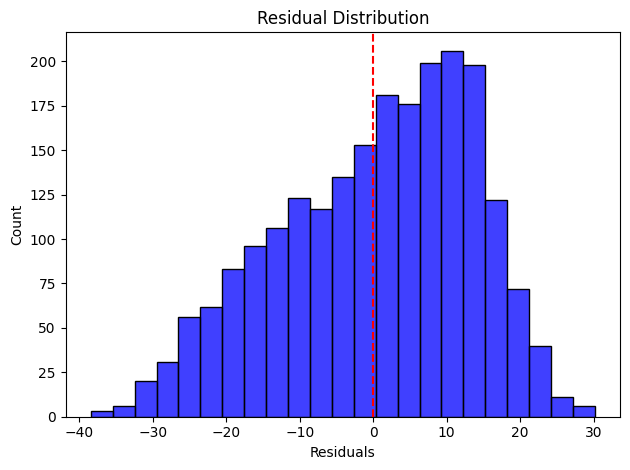

In [64]:
# plot a histogram of residual 
import seaborn as sns 
import matplotlib.pyplot as plt
sns.histplot(get_residual, x="residual", color='blue')
plt.axvline(0, color='red', linestyle="--")
plt.title("Residual Distribution")
plt.xlabel("Residuals")
plt.tight_layout()
plt.show()

In [65]:
# group residuals by reactor_id
groupby_reactor = get_residual.groupby("reactor_id")['residual'].agg(['mean', "std"])
groupby_reactor

,mean,std
reactor_id,,
R1,0.633714,12.762321
R2,-0.899014,12.886497
R3,0.485146,13.595786
R4,0.128817,12.298789
R5,1.345746,12.406977
R6,1.530043,14.069485
R7,-0.649251,13.510641
R8,-0.300947,13.894523


In [ ]:
def rmse(x):
    return np.sqrt(mean_absolute_error(get_residual['y_true'], get_residual['y_pred']))
reactor_status = get_residual.groupby("reactor_id").apply(
    lambda x : pd.Series({
        "Batch Count" : len(x),
        "RMSE" : rmse(x)
    })
)

display(reactor_status)

,Batch Count,RMSE
reactor_id,,
R1,289.0,3.31738
R2,288.0,3.31738
R3,297.0,3.31738
R4,278.0,3.31738
R5,246.0,3.31738
R6,285.0,3.31738
R7,259.0,3.31738
R8,260.0,3.31738


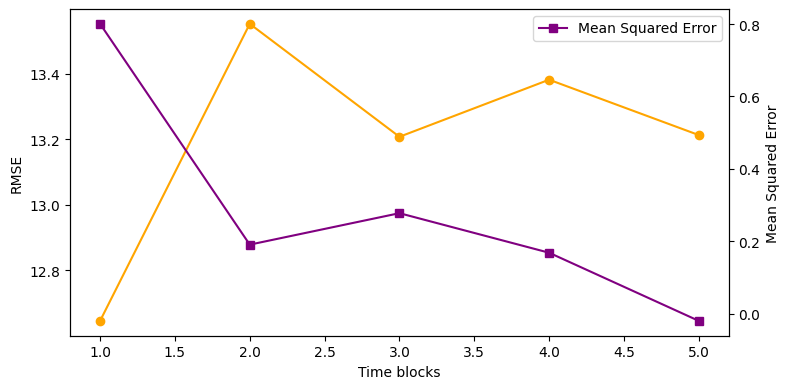

In [67]:
residual = y_test_data - y_final_xgboost
blocks = np.array_split(residual, 5)

rmses = []
mean_blocks = []
for block in blocks:
    rmses.append(np.sqrt(np.mean(block**2)))
    mean_blocks.append(block.mean())

# plot the graphs 
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()

ax1.plot(range(1, 6), rmses, color='orange', marker='o', label='RMSE')
ax2.plot(range(1, 6), mean_blocks, color='purple', marker='s', label='Mean Squared Error')
ax1.set_xlabel("Time blocks")
ax1.set_ylabel("RMSE")
ax2.set_ylabel("Mean Squared Error")
plt.legend()
plt.tight_layout()
plt.show()

In [68]:
batches = X_test_data.copy()
batches['actual'] = y_test_data
batches['predicted'] = y_final_xgboost
batches['residual'] =  y_test_data - y_final_xgboost

# isolate the batches with residual greater that 20
bad_batches = batches[batches['residual'] < -20]
normal_batches = batches[batches['residual'] >= -20 ]

# get the mean of the good and bad batches
print("===============Bad Batches==================")
print(f"Average Yield Mean: {bad_batches['actual'].mean()}")
print(f"Average temp: {bad_batches['temp_c_get_quantille_05'].mean()}")
print(f"Average Purity: {bad_batches['feed_purity'].mean()}")
print(f"Top Reactor :{bad_batches['reactor_id'].mode()[0]}")
print(f"Top Lot: {bad_batches['catalyst_lot'].mode()[0]}")

print("===============Normal Batches==================")
print(f"Average Yield Mean: {normal_batches['actual'].mean()}")
print(f"Average temp: {normal_batches['temp_c_get_quantille_05'].mean()}")
print(f"Average Purity: {normal_batches['feed_purity'].mean()}")
print(f"Top Reactor :{normal_batches['reactor_id'].mode()[0]}")
print(f"Top Lot: {normal_batches['catalyst_lot'].mode()[0]}")

===============Bad Batches==================
Average Yield Mean: 41.21848209817052
Average temp: 42.41362486224468
Average Purity: 0.9714774878851816
Top Reactor :R2
Top Lot: LOT-064
===============Normal Batches==================
Average Yield Mean: 65.47941879591184
Average temp: 42.34322477358955
Average Purity: 0.9695648596660219
Top Reactor :R3
Top Lot: LOT-067


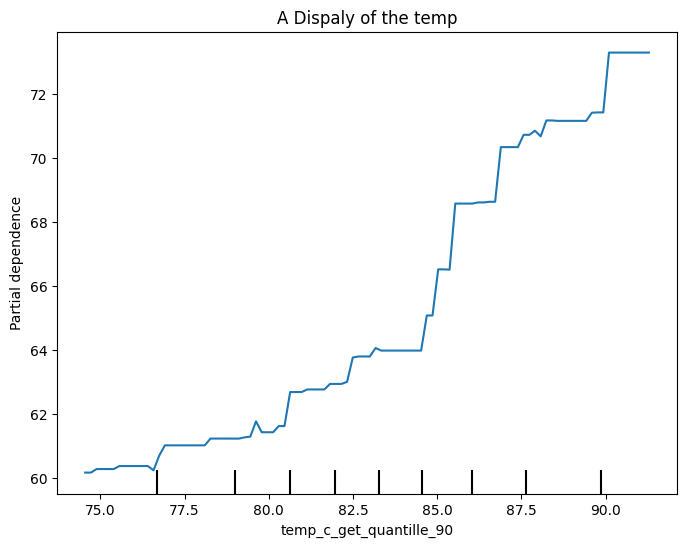

In [70]:
# a partial dependency of the most important feature 
fig, ax = plt.subplots(figsize=(8, 6))
display=PartialDependenceDisplay.from_estimator(
    xgboost_model,
    X_test_data,
    ax=ax,
    features=['temp_c_get_quantille_90']
)
plt.title("A Dispaly of the temp")
plt.show()
